<a href="https://colab.research.google.com/github/DANIAL3304/diabetes_prediction_analysis/blob/main/diabetes_analysis_medium_testing.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

# Diabetes Data Analysis and Prediction

Name: Expert Analyst Task: Predict and identify diabetes based on multiple attributes using 2 datasets. Environment: Google Colab


# Import the packages

In [ ]:
# Step 1: Imports and Setup
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns
import matplotlib.cm as cm
from sklearn.model_selection import train_test_split, RandomizedSearchCV
from sklearn.preprocessing import StandardScaler, MinMaxScaler
from sklearn.metrics import accuracy_score, f1_score, silhouette_score, silhouette_samples, confusion_matrix
from sklearn.decomposition import PCA
from sklearn.tree import DecisionTreeClassifier
from sklearn.ensemble import RandomForestClassifier
from sklearn.linear_model import LogisticRegression
from sklearn.neighbors import KNeighborsClassifier
from sklearn.svm import SVC
from sklearn.naive_bayes import GaussianNB
from sklearn.neural_network import MLPClassifier
from xgboost import XGBClassifier
from sklearn.cluster import KMeans, DBSCAN, AgglomerativeClustering
from mlxtend.frequent_patterns import apriori, association_rules
from imblearn.over_sampling import SMOTE
import warnings
import json
import joblib
from google.colab import drive

warnings.filterwarnings('ignore')

# Set visualization style
sns.set(style="whitegrid")

# Mount Google Drive
drive.mount('/content/drive')
DRIVE_PATH = '/content/drive/MyDrive/Datasets/Project/'
print("Google Drive mounted. Path set to:", DRIVE_PATH)

Mounted at /content/drive
Google Drive mounted. Path set to: /content/drive/MyDrive/Datasets/Project/


# Load dataset ( Biggest and Medium Dataset)

In [ ]:
# Load datasets from Google Drive
try:
    df1 = pd.read_csv(DRIVE_PATH + 'diabetes_binary_5050split_health_indicators_BRFSS2015.csv')
    df2 = pd.read_csv(DRIVE_PATH + 'diabetes_data.csv')
    print("Datasets loaded successfully from Drive.")
except FileNotFoundError:
    print("Files not found in Google Drive Root. Please check the path.")

# Display first few rows and info
print("Dataset 1 Head:")
display(df1.head())
print("Dataset 1 Info:")
print(df1.info())

print("\nDataset 2 Head:")
display(df2.head())
print("Dataset 2 Info:")
print(df2.info())

Datasets loaded successfully from Drive.
Dataset 1 Head:


,Diabetes_binary,HighBP,HighChol,CholCheck,BMI,Smoker,Stroke,HeartDiseaseorAttack,PhysActivity,Fruits,...,AnyHealthcare,NoDocbcCost,GenHlth,MentHlth,PhysHlth,DiffWalk,Sex,Age,Education,Income
0,0.0,1.0,0.0,1.0,26.0,0.0,0.0,0.0,1.0,0.0,...,1.0,0.0,3.0,5.0,30.0,0.0,1.0,4.0,6.0,8.0
1,0.0,1.0,1.0,1.0,26.0,1.0,1.0,0.0,0.0,1.0,...,1.0,0.0,3.0,0.0,0.0,0.0,1.0,12.0,6.0,8.0
2,0.0,0.0,0.0,1.0,26.0,0.0,0.0,0.0,1.0,1.0,...,1.0,0.0,1.0,0.0,10.0,0.0,1.0,13.0,6.0,8.0
3,0.0,1.0,1.0,1.0,28.0,1.0,0.0,0.0,1.0,1.0,...,1.0,0.0,3.0,0.0,3.0,0.0,1.0,11.0,6.0,8.0
4,0.0,0.0,0.0,1.0,29.0,1.0,0.0,0.0,1.0,1.0,...,1.0,0.0,2.0,0.0,0.0,0.0,0.0,8.0,5.0,8.0


Dataset 1 Info:
<class 'pandas.core.frame.DataFrame'>
RangeIndex: 70692 entries, 0 to 70691
Data columns (total 22 columns):
 #   Column                Non-Null Count  Dtype  
---  ------                --------------  -----  
 0   Diabetes_binary       70692 non-null  float64
 1   HighBP                70692 non-null  float64
 2   HighChol              70692 non-null  float64
 3   CholCheck             70692 non-null  float64
 4   BMI                   70692 non-null  float64
 5   Smoker                70692 non-null  float64
 6   Stroke                70692 non-null  float64
 7   HeartDiseaseorAttack  70692 non-null  float64
 8   PhysActivity          70692 non-null  float64
 9   Fruits                70692 non-null  float64
 10  Veggies               70692 non-null  float64
 11  HvyAlcoholConsump     70692 non-null  float64
 12  AnyHealthcare         70692 non-null  float64
 13  NoDocbcCost           70692 non-null  float64
 14  GenHlth               70692 non-null  float64
 15  Men

,age,gender,bmi,bmi_category,systolic,diastolic,blood_pressure_category,cholesterol,cholesterol_category,glucose,diabetes_probability
0,55,Female,29.59,Overweight,112.0,89.5,Hypertension Stage 1,247,High,139,0.65
1,34,Male,30.68,Obesity,106.0,115.0,Hypertension Stage 2,255,High,101,0.60
2,26,Male,15.96,Underweight,96.0,97.0,Hypertension Stage 2,234,Borderline high,97,0.15
3,63,Male,15.61,Underweight,109.6,115.3,Hypertension Stage 2,261,High,143,0.70
4,37,Male,41.54,Obesity,110.0,103.0,Hypertension Stage 2,226,Borderline high,115,0.50


Dataset 2 Info:
<class 'pandas.core.frame.DataFrame'>
RangeIndex: 10000 entries, 0 to 9999
Data columns (total 11 columns):
 #   Column                   Non-Null Count  Dtype  
---  ------                   --------------  -----  
 0   age                      10000 non-null  int64  
 1   gender                   10000 non-null  object 
 2   bmi                      10000 non-null  float64
 3   bmi_category             10000 non-null  object 
 4   systolic                 10000 non-null  float64
 5   diastolic                10000 non-null  float64
 6   blood_pressure_category  10000 non-null  object 
 7   cholesterol              10000 non-null  int64  
 8   cholesterol_category     10000 non-null  object 
 9   glucose                  10000 non-null  int64  
 10  diabetes_probability     10000 non-null  float64
dtypes: float64(4), int64(3), object(4)
memory usage: 859.5+ KB
None


# Data cleaning and data preprocessing

In [ ]:
def clean_df1_survey(df):
    """Cleaning logic for Dataset 1"""
    df = df.copy()

    # Map Age Categories
    age_map = {1:21, 2:27, 3:32, 4:37, 5:42, 6:47, 7:52, 8:57, 9:62, 10:67, 11:72, 12:77, 13:82}
    df['Age_Raw'] = df['Age'].map(age_map)

    # Return standard columns
    return df[['Diabetes_binary', 'HighBP', 'BMI', 'Sex', 'Age_Raw']]

def clean_df2_clinical(df):
    """Cleaning logic for Dataset 2"""
    df = df.copy()

    # Create Target & HighBP
    df['Diabetes_binary'] = (df['diabetes_probability'] > 0.5).astype(int)
    df['HighBP'] = np.where((df['systolic'] > 130) | (df['diastolic'] > 80), 1, 0)

    # Map Sex and rename columns
    df['Sex'] = df['gender'].map({'Male': 1, 'Female': 0})
    df['BMI'] = df['bmi']
    df['Age_Raw'] = df['age']

    return df[['Diabetes_binary', 'HighBP', 'BMI', 'Sex', 'Age_Raw']]

    # Apply cleaning
df1_clean = clean_df1_survey(df1)
df2_clean = clean_df2_clinical(df2)

print("Data Cleaning Complete.")

Data Cleaning Complete.


# Features engineering

Intraction feature

In [ ]:
def add_interactions(df):
    """Logic to create interaction features for metabolic and demographic risk"""
    df = df.copy()

    # 1. Normalize Age
    df['Age_Normalized'] = df['Age_Raw'] / 100.0

   # 2. Metabolic Score
    df['Metabolic_Score'] = df['BMI'] * (df['HighBP'] + 1)

    # 3. Age Weighted BMI
    df['Age_Weighted_BMI'] = df['BMI'] * df['Age_Normalized']

    # 4. Clinical Synergy: Blood Pressure impact as people get older
    df['Age_HighBP'] = df['Age_Raw'] * df['HighBP']

    # Drop intermediate column
    return df.drop(columns=['Age_Raw'])


# Apply the interactions to both datasets
df1_final = add_interactions(df1_clean)
df2_final = add_interactions(df2_clean)

print("Interaction Features Added Successfully.")
print("New Feature List:", df1_final.columns.tolist())
# Display Results
print("\n### Dataset 1 Final ###")
display(df1_final.head())

print("\n### Dataset 2 Final ###")
display(df2_final.head())

Interaction Features Added Successfully.
New Feature List: ['Diabetes_binary', 'HighBP', 'BMI', 'Sex', 'Age_Normalized', 'Metabolic_Score', 'Age_Weighted_BMI', 'Age_HighBP']

### Dataset 1 Final ###


,Diabetes_binary,HighBP,BMI,Sex,Age_Normalized,Metabolic_Score,Age_Weighted_BMI,Age_HighBP
0,0.0,1.0,26.0,1.0,0.37,52.0,9.62,37.0
1,0.0,1.0,26.0,1.0,0.77,52.0,20.02,77.0
2,0.0,0.0,26.0,1.0,0.82,26.0,21.32,0.0
3,0.0,1.0,28.0,1.0,0.72,56.0,20.16,72.0
4,0.0,0.0,29.0,0.0,0.57,29.0,16.53,0.0



### Dataset 2 Final ###


,Diabetes_binary,HighBP,BMI,Sex,Age_Normalized,Metabolic_Score,Age_Weighted_BMI,Age_HighBP
0,1,1,29.59,0,0.55,59.18,16.2745,55
1,1,1,30.68,1,0.34,61.36,10.4312,34
2,0,1,15.96,1,0.26,31.92,4.1496,26
3,1,1,15.61,1,0.63,31.22,9.8343,63
4,0,1,41.54,1,0.37,83.08,15.3698,37


# Check Dataset Size

In [ ]:
# Print the size (Rows, Columns) of the raw data
print("--- Raw Dataset Sizes ---")
print(f"Dataset 1 (Big):    {df1.shape}")
print(f"Dataset 2 (Medium): {df2.shape}")

print("\n--- Final Cleaned Sizes ---")
print(f"Dataset 1 Final:    {df1_final.shape}")
print(f"Dataset 2 Final:    {df2_final.shape}")


--- Raw Dataset Sizes ---
Dataset 1 (Big):    (70692, 22)
Dataset 2 (Medium): (10000, 11)

--- Final Cleaned Sizes ---
Dataset 1 Final:    (70692, 8)
Dataset 2 Final:    (10000, 8)


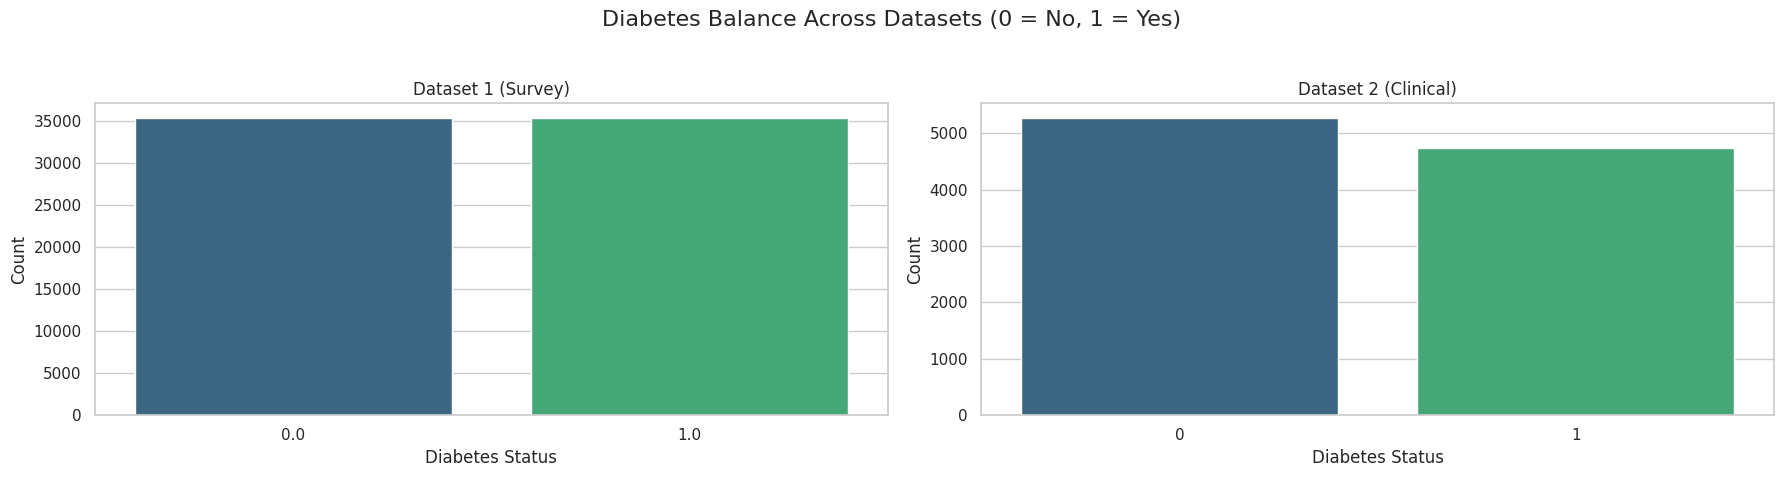

In [ ]:
import matplotlib.pyplot as plt
import seaborn as sns

# Set the design style
sns.set_style("whitegrid")
plt.rcParams.update({'figure.max_open_warning': 0}) # Suppress warnings for cleaner output

# ==========================================
# 1. COMPARE DIABETES PERCENTAGE (All 2 Datasets)
# ==========================================

fig, axes = plt.subplots(1, 2, figsize=(18, 5))
fig.suptitle('Diabetes Balance Across Datasets (0 = No, 1 = Yes)', fontsize=16)

# Helper function to plot counts
def plot_balance(df, ax, title):
    sns.countplot(x='Diabetes_binary', data=df, ax=ax, palette='viridis')
    ax.set_title(title)
    ax.set_xlabel('Diabetes Status')
    ax.set_ylabel('Count')

# Plot all three
plot_balance(df1_final, axes[0], "Dataset 1 (Survey)")
plot_balance(df2_final, axes[1], "Dataset 2 (Clinical)")

plt.tight_layout(rect=[0, 0.03, 1, 0.95])
plt.show()




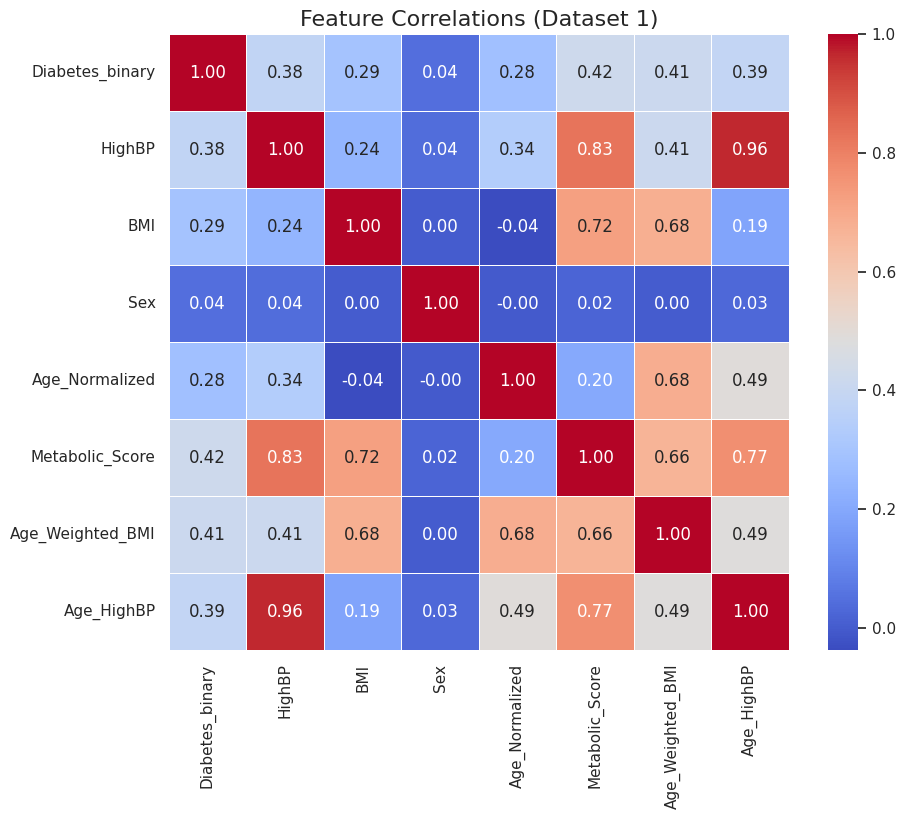

In [ ]:
# ==========================================
# 2. CORRELATION HEATMAP (Using Dataset 1)
# ==========================================
# We use Dataset 1 because it is the largest and most representative.

plt.figure(figsize=(10, 8))
plt.title('Feature Correlations (Dataset 1)', fontsize=16)

# Calculate correlations
corr = df1_final.corr()

# Create Heatmap
sns.heatmap(corr, annot=True, fmt=".2f", cmap='coolwarm', cbar=True, linewidths=0.5)
plt.show()

# Task
Visualize the distributions of 'Age_Normalized', 'BMI', 'Metabolic_Score', 'Age_Weighted_BMI' using histograms, and 'HighBP', 'Sex', 'Male_Obesity_Risk' using count plots across df1_final, df2_final, and df3_final to compare feature distributions, ensuring all plots have appropriate titles and legends.

## Visualize Feature Distributions Across Datasets

### Subtask:
Generate appropriate visualizations (histograms for continuous features and count plots for binary features) for each specified feature across the three final datasets (`df1_final`, `df2_final`, `df3_final`) to compare their distributions. Ensure all plots have appropriate titles and labels.

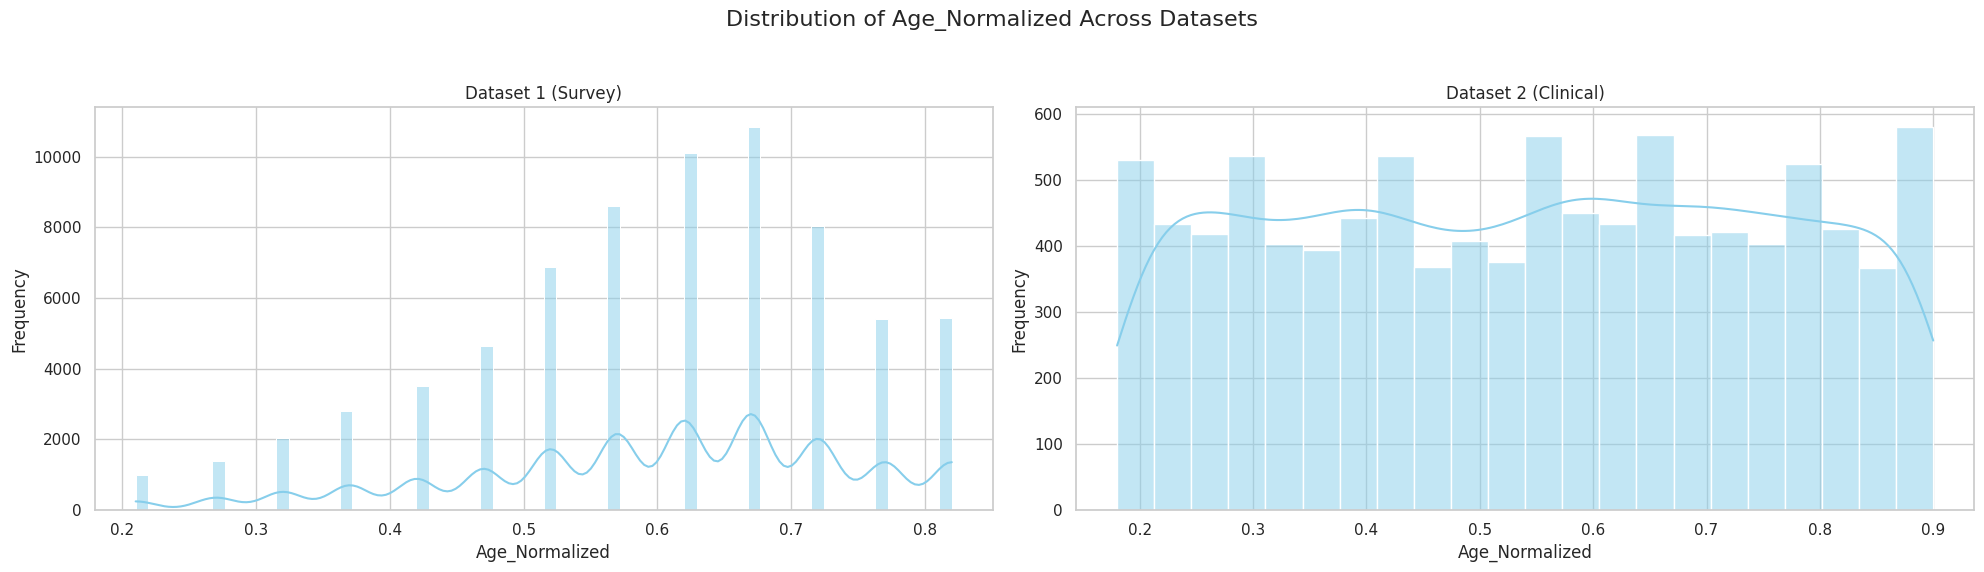

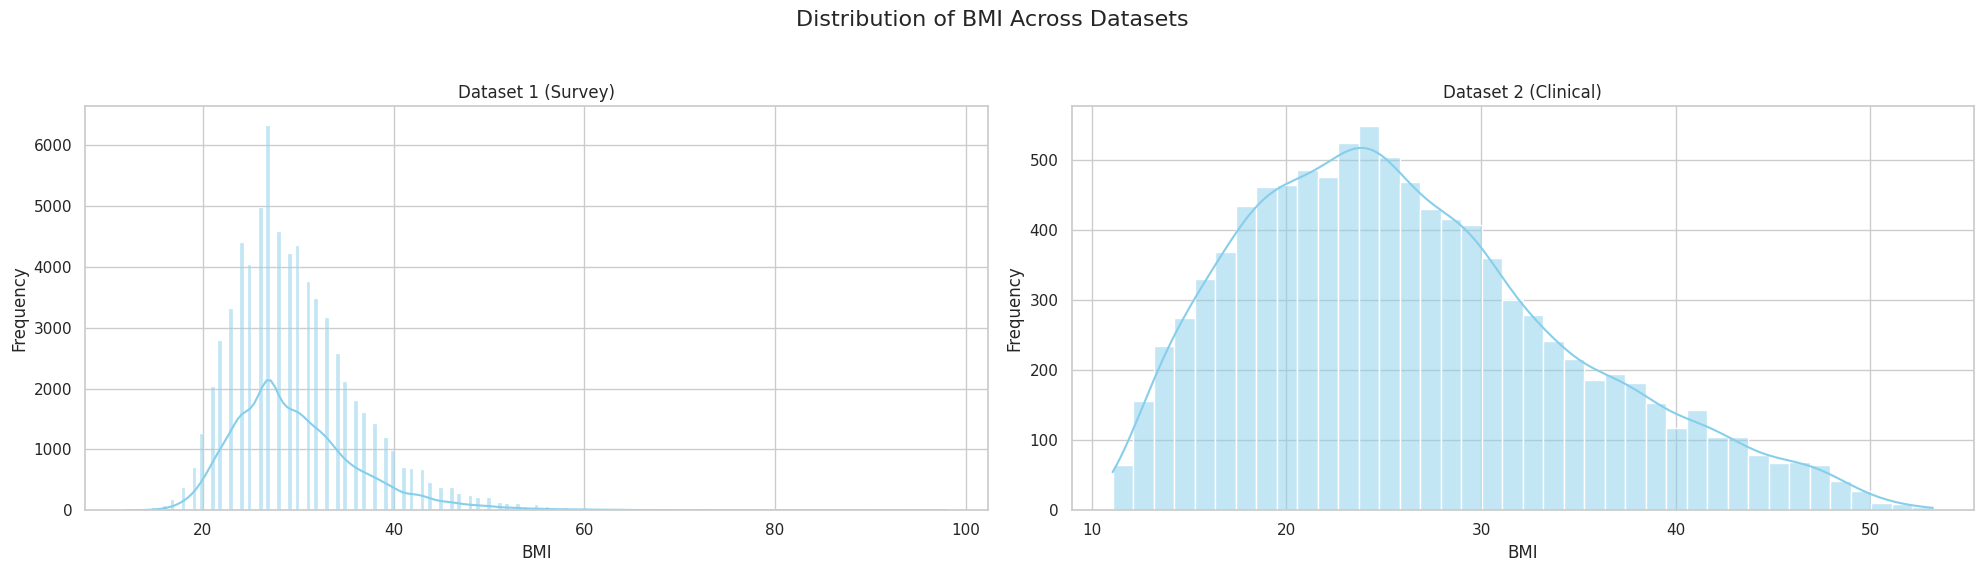

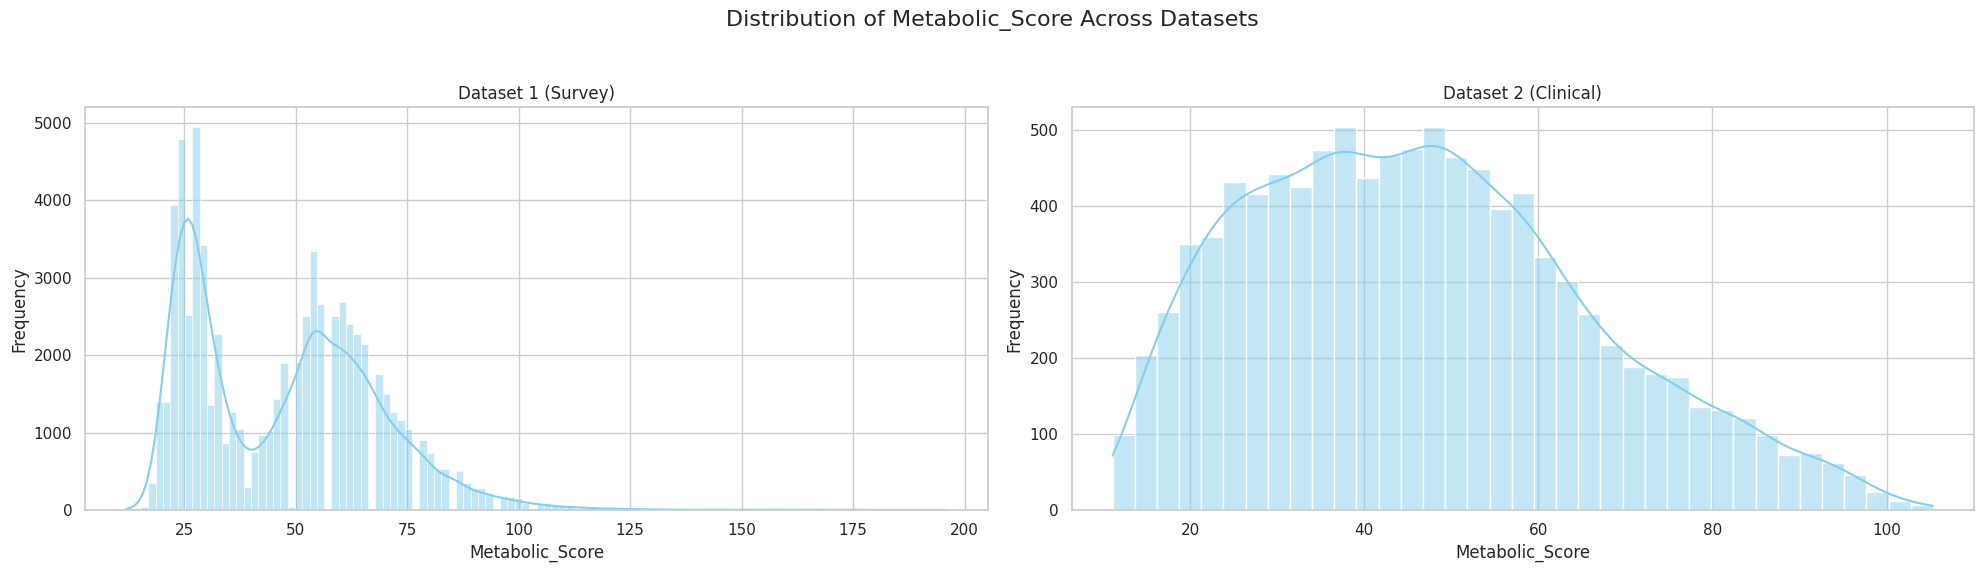

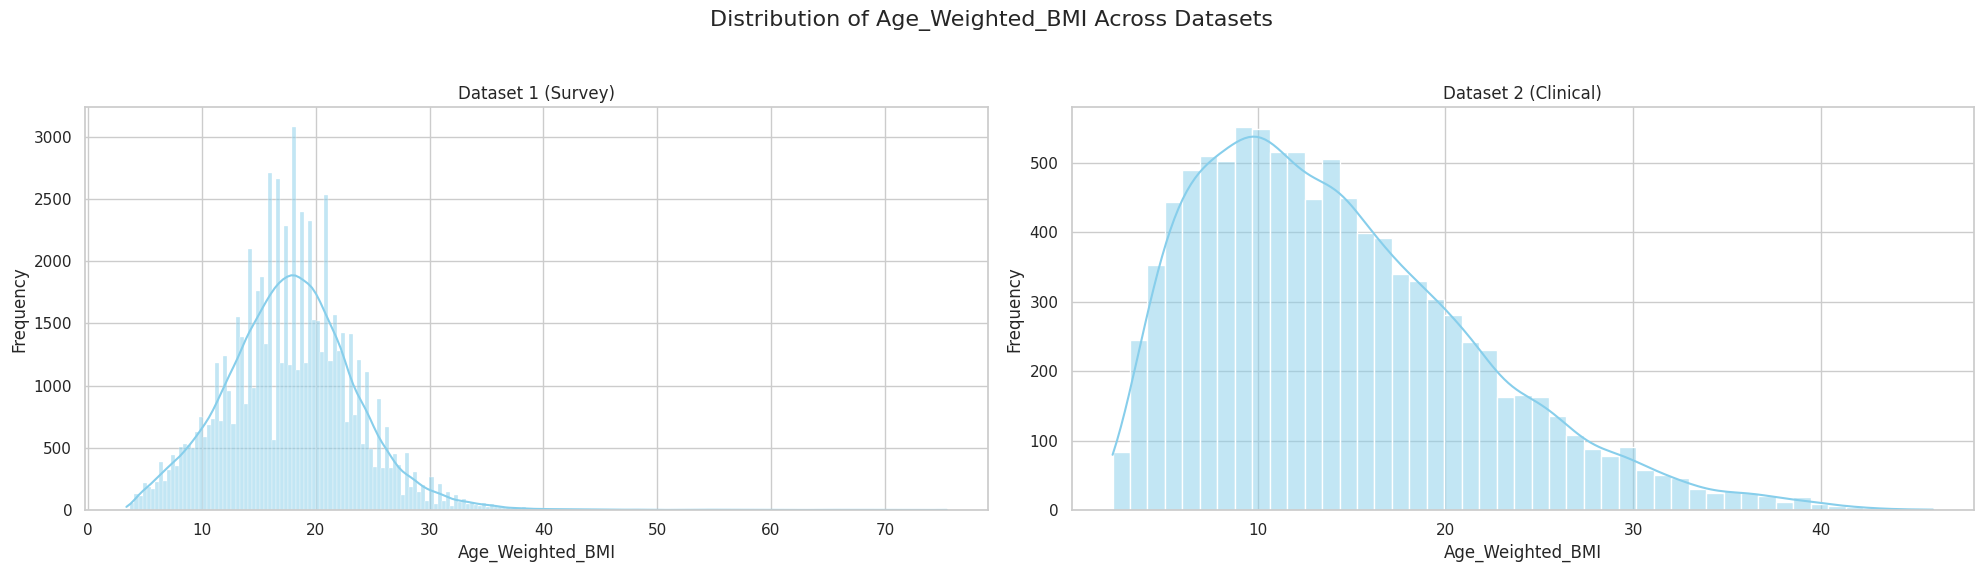

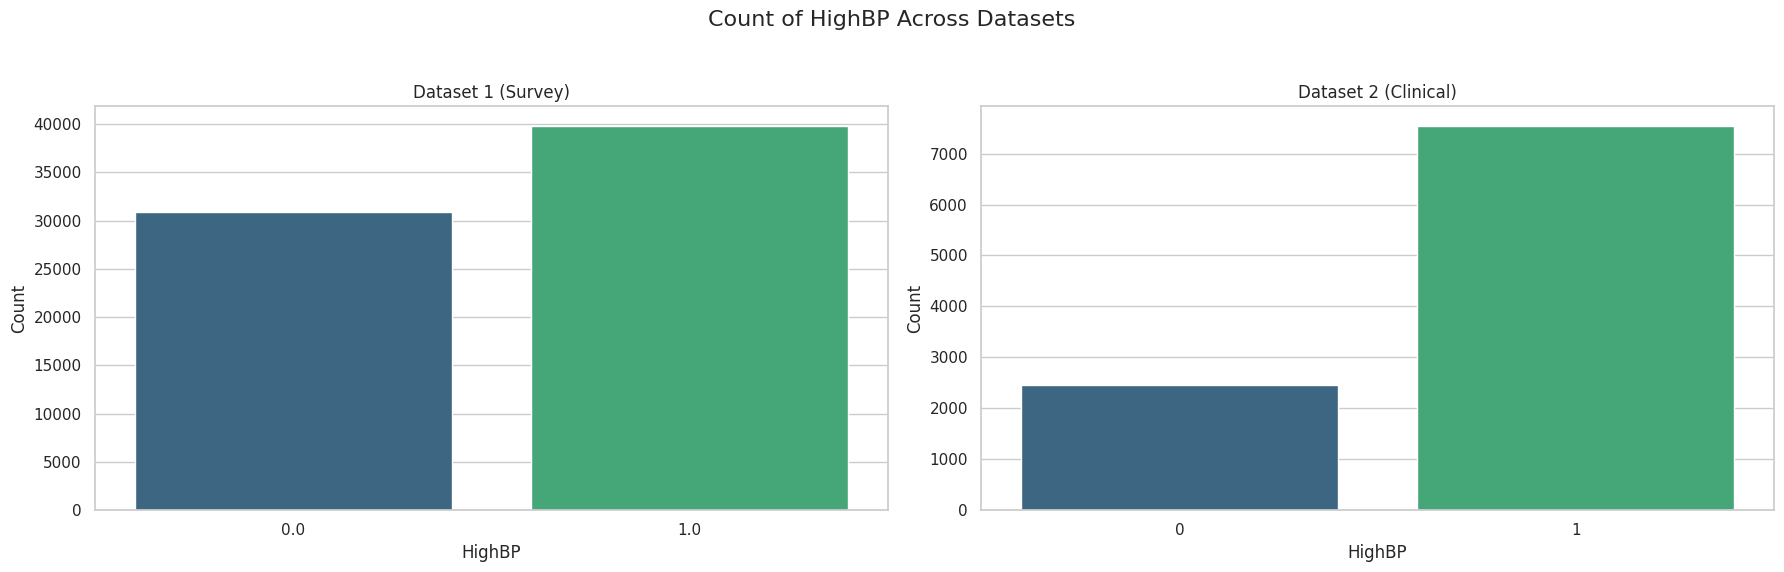

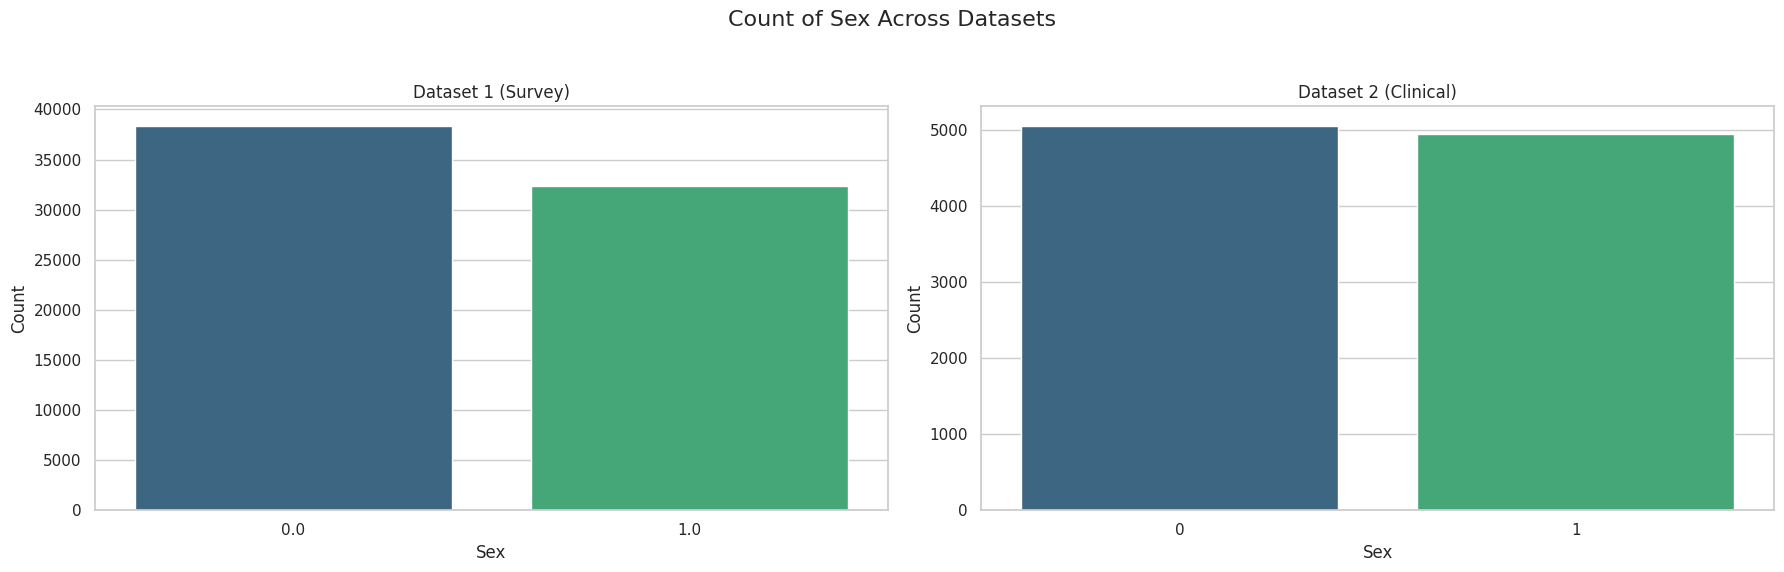

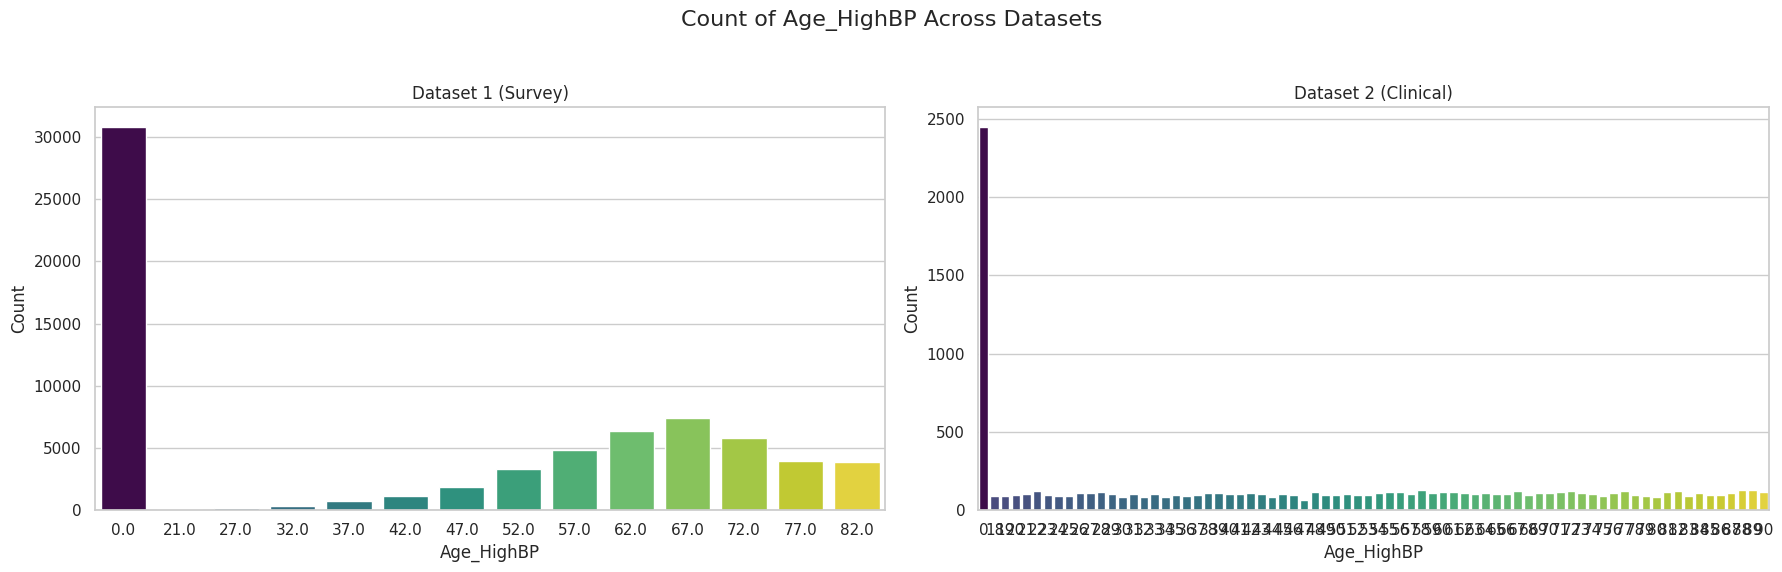

In [ ]:
import matplotlib.pyplot as plt
import seaborn as sns

# Set the design style
sns.set_style("whitegrid")
plt.rcParams.update({'figure.max_open_warning': 0}) # Suppress warnings for cleaner output

# 1. Define lists
continuous_features = ['Age_Normalized', 'BMI', 'Metabolic_Score', 'Age_Weighted_BMI']
binary_features = ['HighBP', 'Sex', 'Age_HighBP']
dataframes = [df1_final, df2_final, ]
df_titles = ['Dataset 1 (Survey)', 'Dataset 2 (Clinical)', ]

# 2. Iterate through continuous features for histograms
for feature in continuous_features:
    fig, axes = plt.subplots(1, 2, figsize=(20, 6))
    fig.suptitle(f'Distribution of {feature} Across Datasets', fontsize=16)

    for i, df in enumerate(dataframes):
        sns.histplot(df[feature], kde=True, ax=axes[i], color='skyblue')
        axes[i].set_title(df_titles[i])
        axes[i].set_xlabel(feature)
        axes[i].set_ylabel('Frequency')

    plt.tight_layout(rect=[0, 0.03, 1, 0.95])
    plt.show()

# 3. Iterate through binary features for count plots
for feature in binary_features:
    fig, axes = plt.subplots(1, 2, figsize=(18, 6))
    fig.suptitle(f'Count of {feature} Across Datasets', fontsize=16)

    for i, df in enumerate(dataframes):
        sns.countplot(x=feature, data=df, ax=axes[i], palette='viridis', hue=feature, legend=False)
        axes[i].set_title(df_titles[i])
        axes[i].set_xlabel(feature)
        axes[i].set_ylabel('Count')

    plt.tight_layout(rect=[0, 0.03, 1, 0.95])
    plt.show()

# Rename and Type Check
Ensuring columns and types match Dataset 1 (Training).

In [ ]:
# Assuming df1_final is your Big (70k) Train set
# and df2_final is your Medium (10k) Test set

# Ensure types match between Big (Train) and Medium (Test)
for col in df1_final.columns:
    if col in df2_final.columns:
        # We cast df2 (Medium) to match the dtypes of df1 (Big)
        df2_final[col] = df2_final[col].astype(df1_final[col].dtype)

print("Dataset 1 (Big/Train) Types:")
print(df1_final.dtypes)
print("\nDataset 2 (Medium/Test) Types:")
print(df2_final.dtypes)

# Confirming they are exactly equal
if all(df1_final.dtypes == df2_final.dtypes):
    print("\nSUCCESS: All data types are perfectly aligned for modeling!")
else:
    print("\nWARNING: Some data types still do not match.")

Dataset 1 (Big/Train) Types:
Diabetes_binary     float64
HighBP              float64
BMI                 float64
Sex                 float64
Age_Normalized      float64
Metabolic_Score     float64
Age_Weighted_BMI    float64
Age_HighBP          float64
dtype: object

Dataset 2 (Medium/Test) Types:
Diabetes_binary     float64
HighBP              float64
BMI                 float64
Sex                 float64
Age_Normalized      float64
Metabolic_Score     float64
Age_Weighted_BMI    float64
Age_HighBP          float64
dtype: object

SUCCESS: All data types are perfectly aligned for modeling!


# Hyperparameter Tuning
Using RandomizedSearchCV to find optimal parameters efficiently without exceeding resource limits. Why: GridSearch is too expensive. RandomizedSearch samples a fixed number of parameter settings.

In [ ]:
# Hyperparameter Tuning
# We will tune distinct models. For brevity, we define a helper function.

def tune_model(model, param_dist, X_train, y_train):
    random_search = RandomizedSearchCV(model, param_distributions=param_dist, n_iter=5, cv=3, scoring='f1', n_jobs=-1, random_state=42)
    random_search.fit(X_train, y_train)
    return random_search.best_estimator_, random_search.best_params_

print("Hyperparameter tuning setup ready.")

Hyperparameter tuning setup ready.


#Supervised Data Mining Algorithms (Classification)
Training on Dataset 1, Testing on medium Dataset.

Starting Model Training & Evaluation...
Creating subsample of 15000 for computationally expensive models (SVM, ANN, kNN)...
Training Decision Tree...
  Best Params: {'min_samples_split': 2, 'max_depth': 10}
  Accuracy: 0.7465, F1: 0.7189


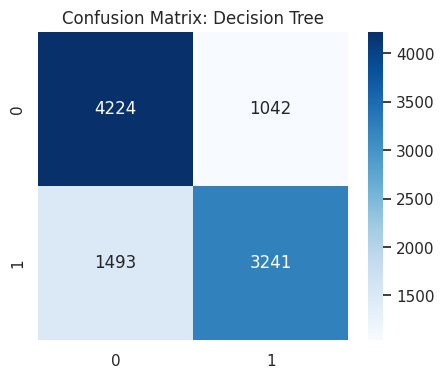

Training Random Forest...
  Best Params: {'n_estimators': 50, 'max_depth': 10}
  Accuracy: 0.7539, F1: 0.7260


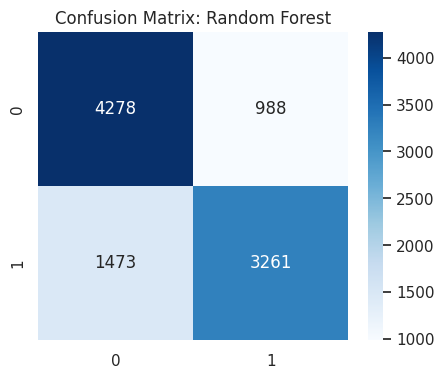

Training XGBoost...
  Best Params: {'n_estimators': 50, 'learning_rate': 0.1}
  Accuracy: 0.7587, F1: 0.7291


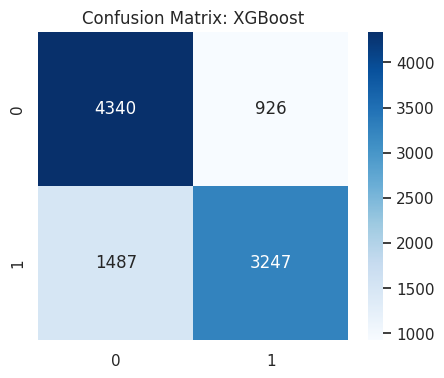

Training Logistic Regression...
  Best Params: {'C': 1.0}
  Accuracy: 0.7611, F1: 0.7232


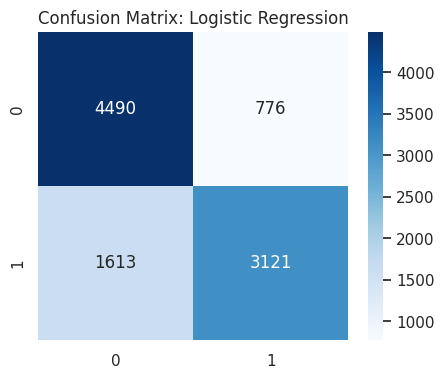

Training kNN...
  Using subsampled data (15000 samples)
  Best Params: {'n_neighbors': 7}
  Accuracy: 0.7046, F1: 0.6764


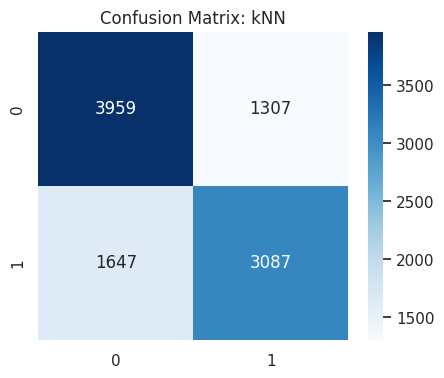

Training SVM...
  Using subsampled data (15000 samples)
  Best Params: {'gamma': 'scale', 'C': 1}
  Accuracy: 0.7643, F1: 0.7469


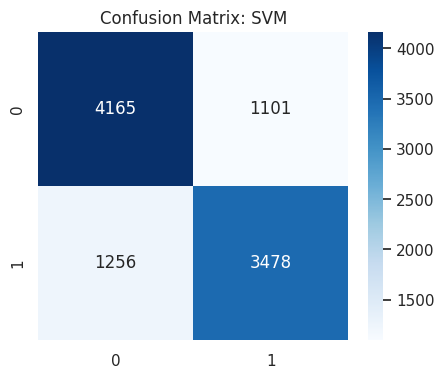

Training GaussianNB...
  Accuracy: 0.7559, F1: 0.7233


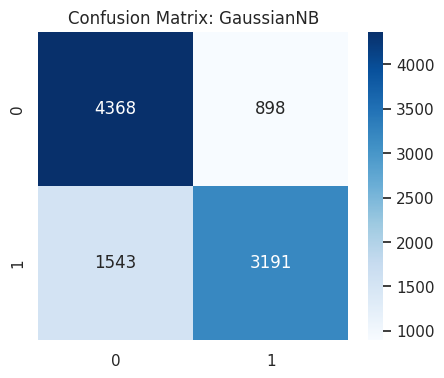

Training ANN (MLP)...
  Using subsampled data (15000 samples)
  Best Params: {'hidden_layer_sizes': (50,), 'alpha': 0.0001}
  Accuracy: 0.7621, F1: 0.7310


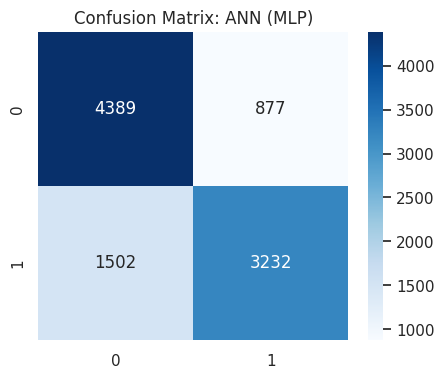

,Algorithm,Accuracy,F1 Score
0,Decision Tree,0.7465,0.718864
1,Random Forest,0.7539,0.726038
2,XGBoost,0.7587,0.729089
3,Logistic Regression,0.7611,0.723207
4,kNN,0.7046,0.676380
5,SVM,0.7643,0.746913
6,GaussianNB,0.7559,0.723337
7,ANN (MLP),0.7621,0.730974


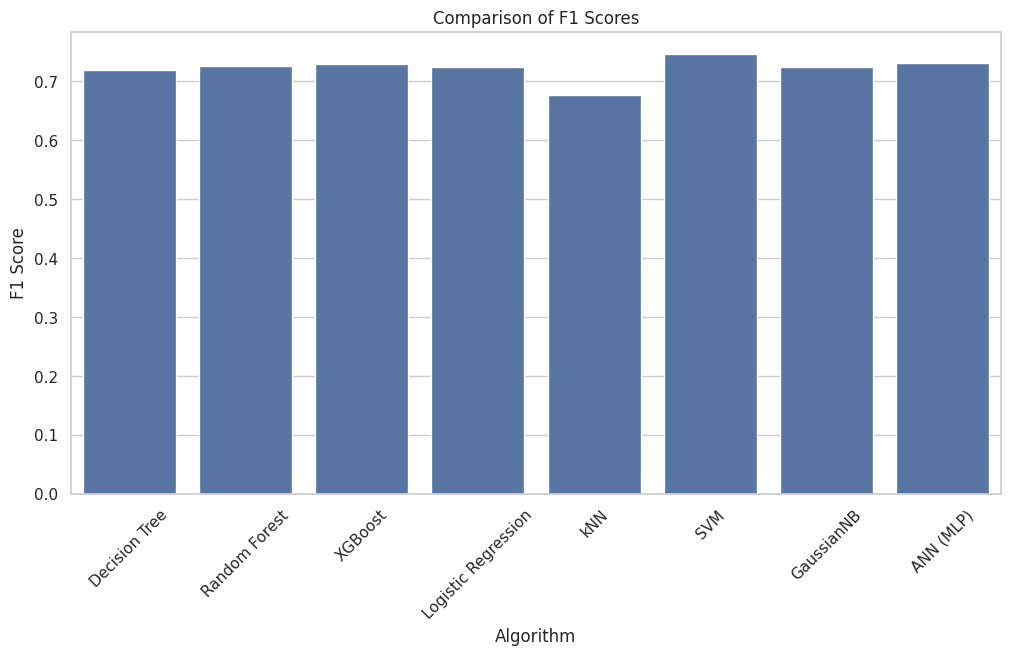

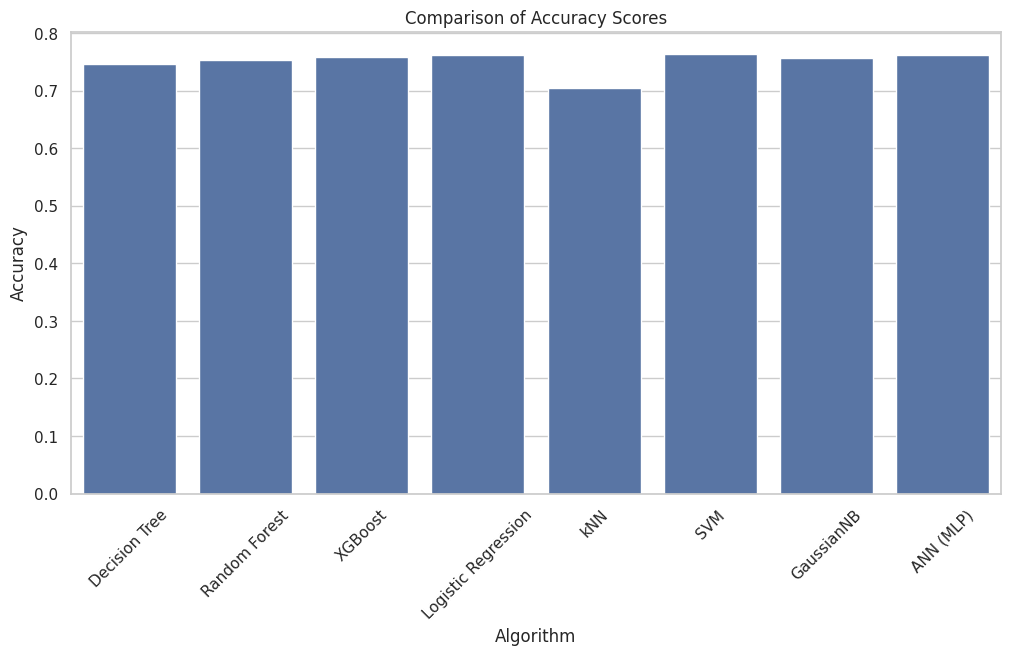

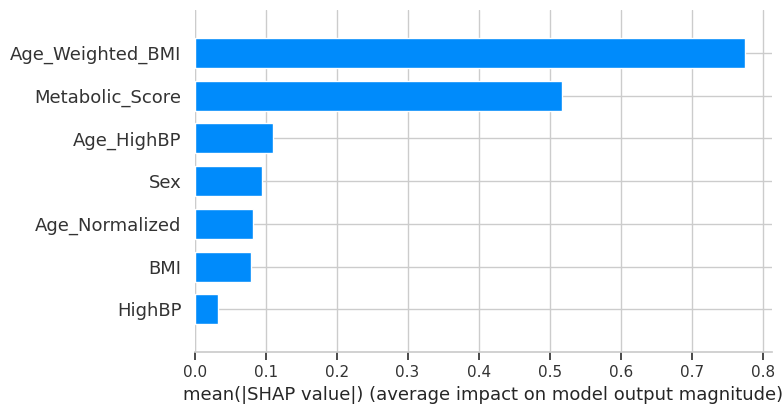

>>> XAI (SHAP) Analysis Complete.
>>> This plot shows which features 'drove' the model's decisions.


In [ ]:
# Prepare Data
X_train = df1_final.drop('Diabetes_binary', axis=1)
y_train = df1_final['Diabetes_binary']
X_test = df2_final.drop('Diabetes_binary', axis=1)
y_test = df2_final['Diabetes_binary']

# Scale features (important for KNN, SVM, ANN)
scaler = StandardScaler()
X_train_scaled = scaler.fit_transform(X_train)
X_test_scaled = scaler.transform(X_test)

results = []

models = {
    "Decision Tree": DecisionTreeClassifier(),
    "Random Forest": RandomForestClassifier(),
    "XGBoost": XGBClassifier(eval_metric='logloss'),
    "Logistic Regression": LogisticRegression(),
    "kNN": KNeighborsClassifier(),
    "SVM": SVC(probability=True, kernel='rbf', cache_size=1000),
    "GaussianNB": GaussianNB(),
    "ANN (MLP)": MLPClassifier(max_iter=200, early_stopping=True)
}

# Define simple param grids for limited tuning
param_grids = {
    "Decision Tree": {'max_depth': [None, 10, 20], 'min_samples_split': [2, 5]},
    "Random Forest": {'n_estimators': [50, 100], 'max_depth': [None, 10]},
    "XGBoost": {'n_estimators': [50, 100], 'learning_rate': [0.01, 0.1]},
    "Logistic Regression": {'C': [0.1, 1.0]},
    "kNN": {'n_neighbors': [3, 5, 7]},
    "SVM": {'C': [0.1, 1], 'gamma': ['scale']},
    "GaussianNB": {},
    "ANN (MLP)": {'hidden_layer_sizes': [(50,), (100,)], 'alpha': [0.0001]}
}

print("Starting Model Training & Evaluation...")

# Dictionary to save trained models for export
trained_models = {}

import time

MAX_SAMPLES = 15000
if len(X_train_scaled) > MAX_SAMPLES:
    print(f"Creating subsample of {MAX_SAMPLES} for computationally expensive models (SVM, ANN, kNN)...")
    # Stratified sample
    indices = np.random.choice(len(X_train_scaled), MAX_SAMPLES, replace=False)
    X_train_sub = X_train_scaled[indices]
    y_train_sub = y_train.iloc[indices]
else:
    X_train_sub = X_train_scaled
    y_train_sub = y_train

for name, model in models.items():
    start_time = time.time()
    print(f"Training {name}...")

    # Select correctly scaled/sampled data
    if name in ["kNN", "SVM", "ANN (MLP)"]:
        # Use subsampled scaled data
        X_tr, y_tr = X_train_sub, y_train_sub
        X_te = X_test_scaled
        print(f"  Using subsampled data ({len(X_tr)} samples)")
    elif name == "Logistic Regression":
        X_tr, y_tr = X_train_scaled, y_train
        X_te = X_test_scaled
    else:
        # Tree models handle large data better, use full unscaled (or scaled doesn't matter much)
        X_tr, y_tr = X_train, y_train
        X_te = X_test

    # Hyperparameter Tuning
    if name in param_grids and param_grids[name]:
        best_model, best_params = tune_model(model, param_grids[name], X_tr, y_tr)
        print(f"  Best Params: {best_params}")
    else:
        best_model = model
        best_model.fit(X_tr, y_tr)

    # Prediction
    y_pred = best_model.predict(X_te)

    # Metrics
    acc = accuracy_score(y_test, y_pred)
    f1 = f1_score(y_test, y_pred)

    results.append({
        "Algorithm": name,
        "Accuracy": acc,
        "F1 Score": f1
    })

    trained_models[name] = best_model

    print(f"  Accuracy: {acc:.4f}, F1: {f1:.4f}")

    # Visualization
    conf_matrix = confusion_matrix(y_test, y_pred)
    plt.figure(figsize=(5, 4))
    sns.heatmap(conf_matrix, annot=True, fmt='d', cmap='Blues')
    plt.title(f'Confusion Matrix: {name}')
    plt.show()

# Comparison Visualization
results_df = pd.DataFrame(results)
display(results_df)

plt.figure(figsize=(12, 6))
sns.barplot(x='Algorithm', y='F1 Score', data=results_df)
plt.title('Comparison of F1 Scores')
plt.xticks(rotation=45)
plt.show()

plt.figure(figsize=(12, 6))
sns.barplot(x='Algorithm', y='Accuracy', data=results_df)
plt.title('Comparison of Accuracy Scores')
plt.xticks(rotation=45)
plt.show()

import shap

# 1. Select a model to explain (e.g., XGBoost or Random Forest)
model_to_explain = trained_models['XGBoost']

# 2. Initialize the Explainer
explainer = shap.Explainer(model_to_explain)
shap_values = explainer(X_test)

# 3. Visualization: Summary Plot
plt.figure(figsize=(10, 6))
shap.summary_plot(shap_values, X_test, plot_type="bar")
plt.show()

print(">>> XAI (SHAP) Analysis Complete.")
print(">>> This plot shows which features 'drove' the model's decisions.")

#Clustering Data Mining Algorithms
Evaluate Silhouette Score and Visualize Clusters using PCA (2D projection).



Starting Clustering with Parameter Tuning...

Finalizing k-Means...


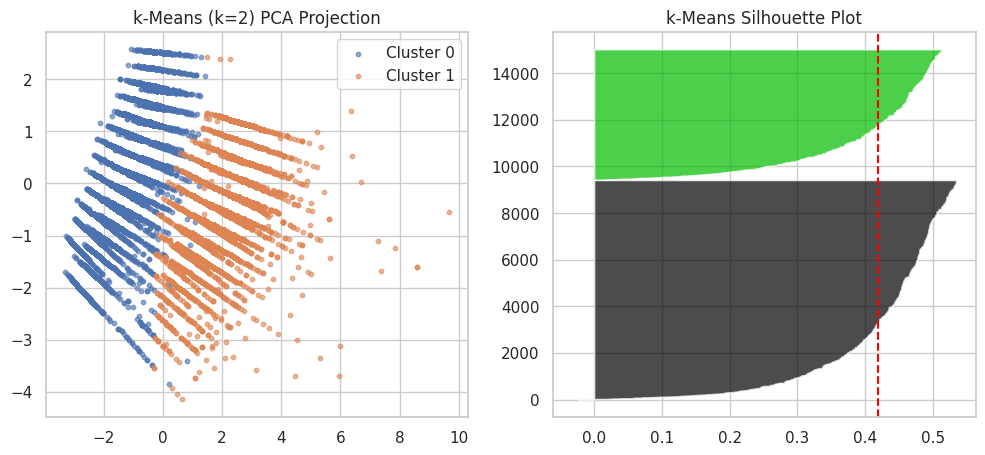

>>> k-Means Analysis Complete.
>>> Final Silhouette Score for k-Means: 0.4184

--------------------------------------------------
Finalizing Hierarchical...


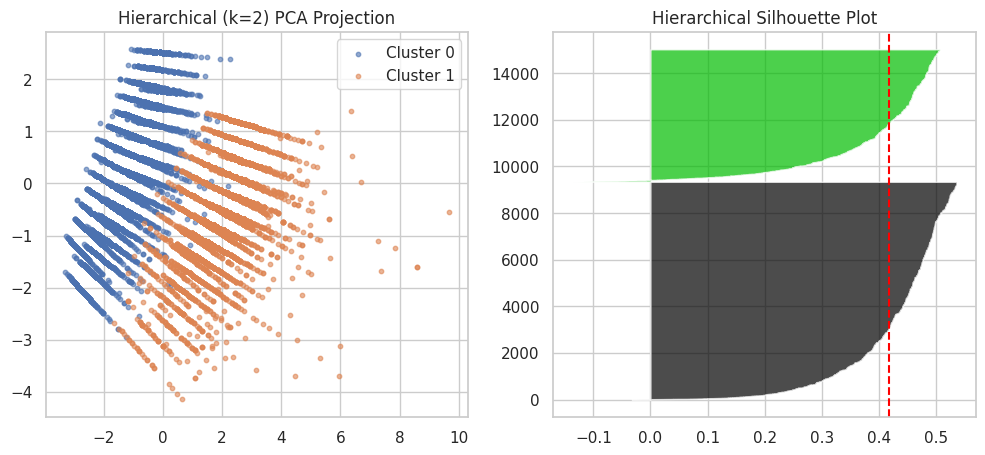

>>> Hierarchical Analysis Complete.
>>> Final Silhouette Score for Hierarchical: 0.4178

--------------------------------------------------
Finalizing DBSCAN...


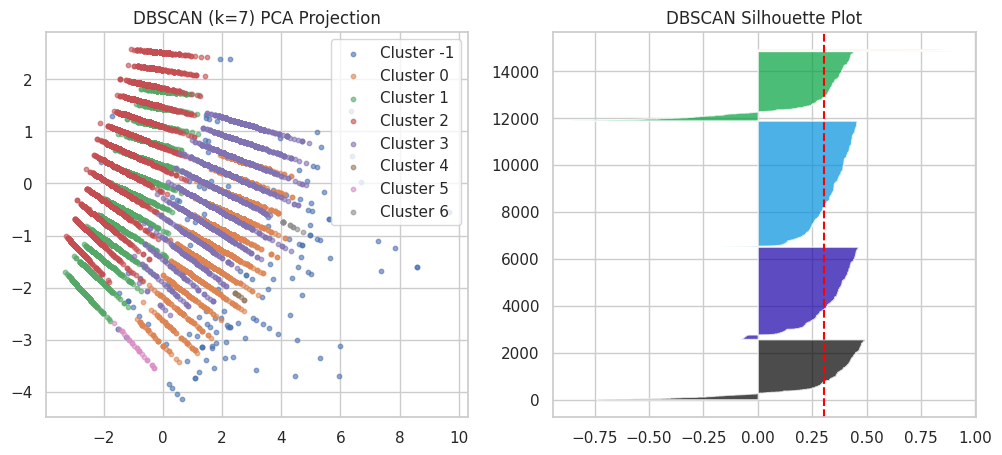

>>> DBSCAN Analysis Complete.
>>> Final Silhouette Score for DBSCAN: 0.3065

--------------------------------------------------

       CLUSTERING PERFORMANCE SUMMARY
Algorithm            | Silhouette Score
----------------------------------------
k-Means              | 0.4184         
Hierarchical         | 0.4178         
DBSCAN               | 0.3065         


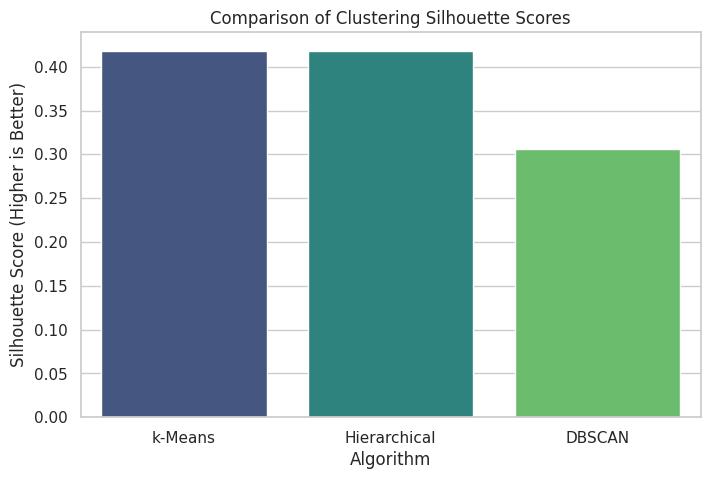


--- XAI for Clustering: Surrogate Decision Tree ---


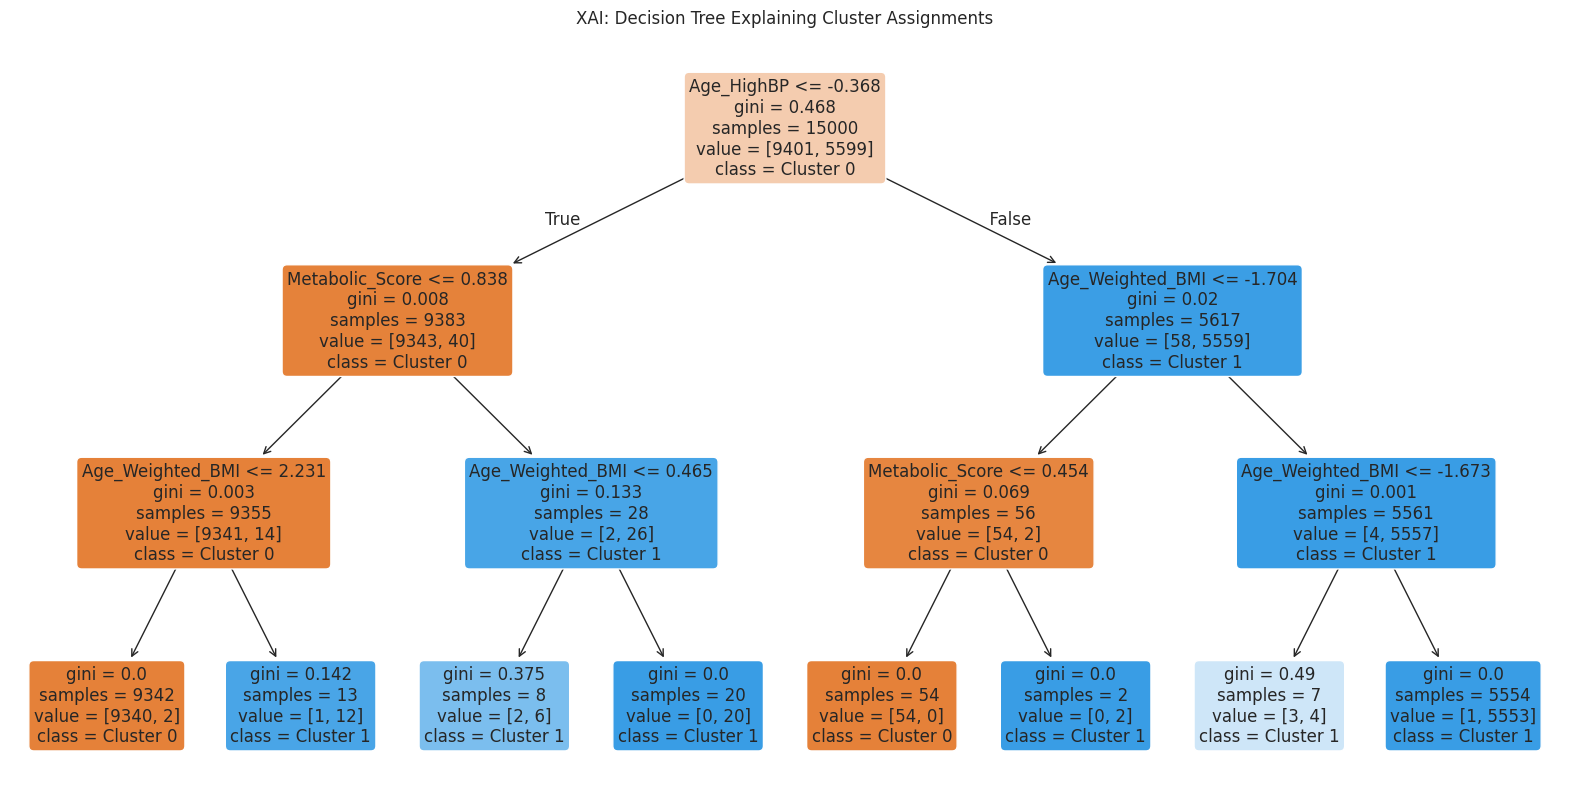

>>> XAI Insight: This tree shows the 'Rules' for each cluster.
>>> Example: If BMI > 30 and Metabolic_Score > 50, assigned to Cluster 1.


In [ ]:
# --- 1. Prepare Data ---
X_cluster = X_train_scaled[:15000]
pca = PCA(n_components=2)
X_pca = pca.fit_transform(X_cluster)

# --- 2. Define Tuning Ranges ---
k_range = range(2, 6)
cluster_results = []
best_models = {}

print("Starting Clustering with Parameter Tuning...\n")

# --- 3. Tuning k-Means ---
best_km_score, best_km_k = -1, 2
for k in k_range:
    km = KMeans(n_clusters=k, random_state=42).fit(X_cluster)
    score = silhouette_score(X_cluster, km.labels_)
    if score > best_km_score:
        best_km_score, best_km_k = score, k
best_models["k-Means"] = KMeans(n_clusters=best_km_k, random_state=42)

# --- 4. Tuning Hierarchical ---
best_agg_score, best_agg_k = -1, 2
for k in k_range:
    agg = AgglomerativeClustering(n_clusters=k).fit(X_cluster)
    score = silhouette_score(X_cluster, agg.labels_)
    if score > best_agg_score:
        best_agg_score, best_agg_k = score, k
best_models["Hierarchical"] = AgglomerativeClustering(n_clusters=best_agg_k)

# --- 5. DBSCAN ---
best_models["DBSCAN"] = DBSCAN(eps=0.5, min_samples=5)

# --- 6. Visualization & Scoring Loop ---
for name, model in best_models.items():
    print(f"Finalizing {name}...")
    labels = model.fit_predict(X_cluster)
    unique_labels = np.unique(labels)
    n_clusters = len(unique_labels[unique_labels != -1])

    if n_clusters > 1:
        score = silhouette_score(X_cluster, labels)

        # Plotting
        plt.figure(figsize=(12, 5))
        plt.subplot(1, 2, 1)
        for i in unique_labels:
            plt.scatter(X_pca[labels == i, 0], X_pca[labels == i, 1], label=f'Cluster {i}', alpha=0.6, s=10)
        plt.title(f'{name} (k={n_clusters}) PCA Projection')
        plt.legend()

        plt.subplot(1, 2, 2)
        sample_vals = silhouette_samples(X_cluster, labels)
        y_lower = 10
        for i in unique_labels:
            if i == -1: continue
            ith_vals = sample_vals[labels == i]
            ith_vals.sort()
            y_upper = y_lower + len(ith_vals)
            color = cm.nipy_spectral(float(i) / n_clusters)
            plt.fill_betweenx(np.arange(y_lower, y_upper), 0, ith_vals, facecolor=color, alpha=0.7)
            y_lower = y_upper + 10
        plt.axvline(x=score, color="red", linestyle="--")
        plt.title(f'{name} Silhouette Plot')
        plt.show()

        # DISPLAY SCORE AFTER VISUAL
        print(f">>> {name} Analysis Complete.")
        print(f">>> Final Silhouette Score for {name}: {score:.4f}\n")
        print("-" * 50)
    else:
        score = -1
        print(f"!!! {name} failed to find valid clusters.\n")

    cluster_results.append({"Algorithm": name, "Silhouette Score": score})

# --- 7. Final Comparison (Chart and Text) ---
cluster_df = pd.DataFrame(cluster_results)

# Final Summary Table in Text
print("\n" + "="*40)
print("       CLUSTERING PERFORMANCE SUMMARY")
print("="*40)
print(f"{'Algorithm':<20} | {'Silhouette Score':<15}")
print("-" * 40)
for result in cluster_results:
    score_text = f"{result['Silhouette Score']:.4f}" if result['Silhouette Score'] != -1 else "N/A"
    print(f"{result['Algorithm']:<20} | {score_text:<15}")
print("="*40)

# Bar Chart
plt.figure(figsize=(8, 5))
sns.barplot(x='Algorithm', y='Silhouette Score', data=cluster_df, palette='viridis')
plt.title('Comparison of Clustering Silhouette Scores')
plt.ylabel('Silhouette Score (Higher is Better)')
plt.show()

from sklearn.tree import plot_tree, DecisionTreeClassifier

print("\n--- XAI for Clustering: Surrogate Decision Tree ---")

# 1. Use a simple Decision Tree to 'learn' why the models grouped data this way
# We use the labels from your best k-Means model as the target
km_labels = best_models["k-Means"].fit_predict(X_cluster)

# Train the 'Explainer'
explainer_tree = DecisionTreeClassifier(max_depth=3)
explainer_tree.fit(X_cluster, km_labels)

# 2. Visualize the logic
plt.figure(figsize=(20,10))
plot_tree(explainer_tree,
          feature_names=X_train.columns,
          class_names=[f'Cluster {i}' for i in np.unique(km_labels)],
          filled=True, rounded=True, fontsize=12)
plt.title("XAI: Decision Tree Explaining Cluster Assignments")
plt.show()

print(">>> XAI Insight: This tree shows the 'Rules' for each cluster.")
print(">>> Example: If BMI > 30 and Metabolic_Score > 50, assigned to Cluster 1.")

# Association Rule Data Mining
Using Apriori and FP-Growth

Association Data Ready with features: Metabolic_Risk, Age_BMI_Risk, and Age_BP_Risk.
Starting Association Rule Mining with Support Tuning...

Tuning Apriori...


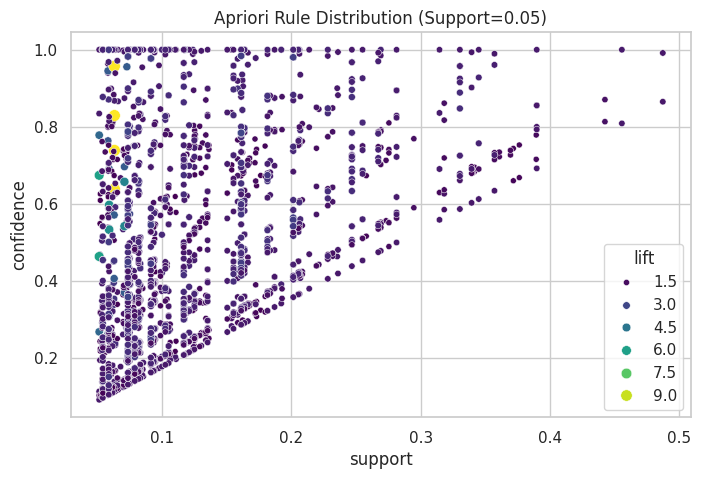

>>> Apriori Analysis Complete.
>>> Average Lift: 1.8394
>>> Average Confidence: 0.5016
>>> Number of Rules: 2966

--------------------------------------------------
Tuning FP-Growth...


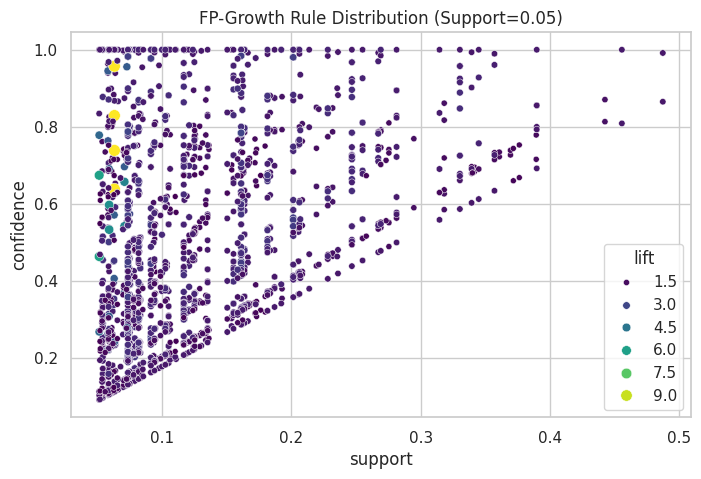

>>> FP-Growth Analysis Complete.
>>> Average Lift: 1.8394
>>> Average Confidence: 0.5016
>>> Number of Rules: 2966

--------------------------------------------------

       ASSOCIATION RULES PERFORMANCE SUMMARY
Algorithm    | Lift     | Conf     | Rules  | Support 
--------------------------------------------------
Apriori      | 1.8394   | 0.5016   | 2966   | 0.05    
FP-Growth    | 1.8394   | 0.5016   | 2966   | 0.05    


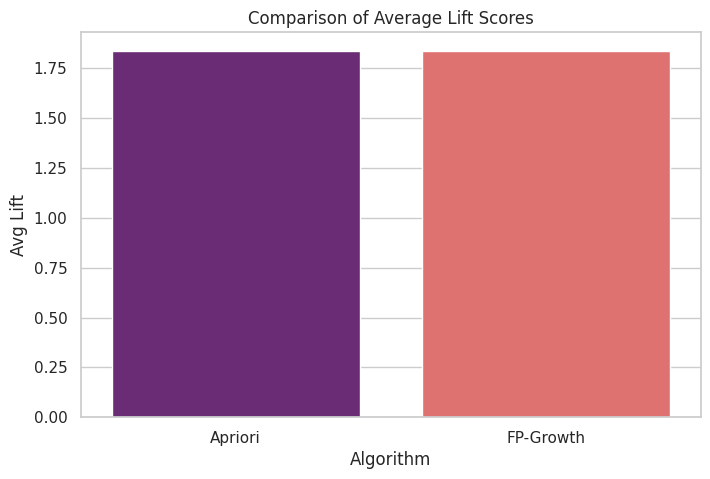


--- XAI for Association: Parallel Coordinates Logic ---


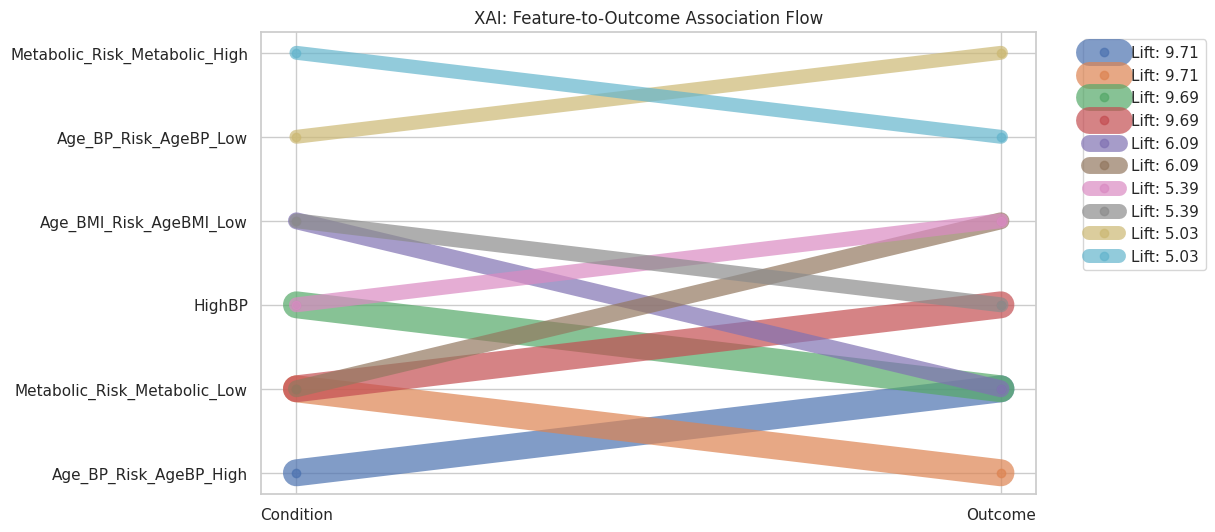

>>> XAI Insight: The thickness of the lines represents the 'Lift'.
>>> Thicker lines show stronger causal associations found by the AI.


In [ ]:
# --- 1. Prepare Data (Using your specific Interaction Features) ---
df_assoc = df1_final.copy()

# A. Binning Standard Variables
df_assoc['BMI_Bin'] = pd.cut(df_assoc['BMI'], bins=[0, 18.5, 25, 30, 100],
                             labels=['Underweight', 'Normal', 'Overweight', 'Obese'])

# B. Binning YOUR Interaction Features (2, 3, and 4)
# We use the median to split them into 'High' and 'Low' categories
# 2. Metabolic Score
df_assoc['Metabolic_Risk'] = (df_assoc['Metabolic_Score'] > df_assoc['Metabolic_Score'].median()).map({True: 'Metabolic_High', False: 'Metabolic_Low'})

# 3. Age Weighted BMI
df_assoc['Age_BMI_Risk'] = (df_assoc['Age_Weighted_BMI'] > df_assoc['Age_Weighted_BMI'].median()).map({True: 'AgeBMI_High', False: 'AgeBMI_Low'})

# 4. Age HighBP Synergy
df_assoc['Age_BP_Risk'] = (df_assoc['Age_HighBP'] > df_assoc['Age_HighBP'].median()).map({True: 'AgeBP_High', False: 'AgeBP_Low'})

# C. One-hot encode standard + your interactions
# Note: We include Sex as a categorical baseline
cols_to_encode = ['HighBP', 'Diabetes_binary', 'Sex', 'BMI_Bin', 'Metabolic_Risk', 'Age_BMI_Risk', 'Age_BP_Risk']
df_assoc_encoded = pd.get_dummies(df_assoc[cols_to_encode])

# Convert to boolean for Apriori/FP-Growth
df_assoc_bool = df_assoc_encoded.astype(bool)

print("Association Data Ready with features: Metabolic_Risk, Age_BMI_Risk, and Age_BP_Risk.")

# --- 2. Define Tuning Logic ---
# We tune 'min_support' to find a balanced number of rules (not too many, not zero)
support_levels = [0.2, 0.1, 0.05]
assoc_results = []
best_rules = {}

print("Starting Association Rule Mining with Support Tuning...\n")

# --- 3. Algorithms Loop ---
for algo_name in ["Apriori", "FP-Growth"]:
    print(f"Tuning {algo_name}...")
    best_lift = 0
    final_rules = pd.DataFrame()
    chosen_support = 0

    for sup in support_levels:
        if algo_name == "Apriori":
            frequent_itemsets = apriori(df_assoc_bool, min_support=sup, use_colnames=True)
        else:
            from mlxtend.frequent_patterns import fpgrowth
            frequent_itemsets = fpgrowth(df_assoc_bool, min_support=sup, use_colnames=True)

        rules = association_rules(frequent_itemsets, metric="lift", min_threshold=1.2)

        # If we found a manageable number of rules (between 5 and 50), we stop
        if 5 <= len(rules) <= 50:
            final_rules = rules
            chosen_support = sup
            break
        elif len(rules) > 50: # If too many rules, try a higher support in next loop
            final_rules = rules
            chosen_support = sup

    if not final_rules.empty:
        avg_lift = final_rules['lift'].mean()
        avg_conf = final_rules['confidence'].mean()
        best_rules[algo_name] = final_rules
    else:
        avg_lift, avg_conf = 0, 0

    assoc_results.append({
        "Algorithm": algo_name,
        "Avg Lift": avg_lift,
        "Avg Confidence": avg_conf,
        "Rules Found": len(final_rules),
        "Best Support": chosen_support
    })

    # --- 4. Visualization ---
    if not final_rules.empty:
        plt.figure(figsize=(8, 5))
        sns.scatterplot(x="support", y="confidence", size="lift", data=final_rules, hue="lift", palette="viridis")
        plt.title(f"{algo_name} Rule Distribution (Support={chosen_support})")
        plt.grid(True)
        plt.show()

        print(f">>> {algo_name} Analysis Complete.")
        print(f">>> Average Lift: {avg_lift:.4f}")
        print(f">>> Average Confidence: {avg_conf:.4f}")
        print(f">>> Number of Rules: {len(final_rules)}\n")
        print("-" * 50)

# --- 5. Final Text Comparison ---
assoc_df = pd.DataFrame(assoc_results)
print("\n" + "="*50)
print("       ASSOCIATION RULES PERFORMANCE SUMMARY")
print("="*50)
print(f"{'Algorithm':<12} | {'Lift':<8} | {'Conf':<8} | {'Rules':<6} | {'Support':<8}")
print("-" * 50)
for _, row in assoc_df.iterrows():
    print(f"{row['Algorithm']:<12} | {row['Avg Lift']:<8.4f} | {row['Avg Confidence']:<8.4f} | {int(row['Rules Found']):<6} | {row['Best Support']:<8}")
print("="*50)

# Final Lift Bar Chart
plt.figure(figsize=(8, 5))
sns.barplot(x='Algorithm', y='Avg Lift', data=assoc_df, palette='magma')
plt.title('Comparison of Average Lift Scores')
plt.show()

from pandas.plotting import parallel_coordinates

print("\n--- XAI for Association: Parallel Coordinates Logic ---")

# 1. Take your top 10 most 'important' rules (highest lift)
top_rules = best_rules["FP-Growth"].sort_values(by='lift', ascending=False).head(10)

# 2. We transform the rules into a flow-based visualization
# This shows the path from Antecedents -> Consequents
def rules_to_coordinates(rules):
    data = []
    for _, row in rules.iterrows():
        ant = list(row['antecedents'])[0]
        con = list(row['consequents'])[0]
        data.append({'From': ant, 'To': con, 'Lift': row['lift']})
    return pd.DataFrame(data)

coords_df = rules_to_coordinates(top_rules)

plt.figure(figsize=(10, 6))
# This plot shows how features 'flow' into a diabetes diagnosis
for i, row in coords_df.iterrows():
    plt.plot(['Condition', 'Outcome'], [row['From'], row['To']],
             marker='o', linewidth=row['Lift']*2, alpha=0.7, label=f"Lift: {row['Lift']:.2f}")

plt.title("XAI: Feature-to-Outcome Association Flow")
plt.legend(bbox_to_anchor=(1.05, 1), loc='upper left')
plt.grid(True, axis='x')
plt.show()

print(">>> XAI Insight: The thickness of the lines represents the 'Lift'.")
print(">>> Thicker lines show stronger causal associations found by the AI.")

# Final Experiment Report
Summary of all models.

In [ ]:
final_report = pd.concat([results_df, cluster_df, assoc_df], axis=0, sort=False)
display(final_report)

# Save results to JSON and Model to Pickle in Google Drive
results_dict = {
    "supervised": results,
    "clustering": cluster_results,
    "association": assoc_results
}

# Save Results
with open(DRIVE_PATH + 'experiment_results.json', 'w') as f:
    json.dump(results_dict, f)

# Save Scaler
joblib.dump(scaler, DRIVE_PATH + 'scaler.pkl')

# Save Model
if "Random Forest" in trained_models:
    joblib.dump(trained_models["Random Forest"], DRIVE_PATH + 'diabetes_model.pkl')

print(f"Results and Models saved to {DRIVE_PATH}")

,Algorithm,Accuracy,F1 Score,Silhouette Score,Avg Lift,Avg Confidence,Rules Found,Best Support
0,Decision Tree,0.7466,0.718131,NaN,NaN,NaN,NaN,NaN
1,Random Forest,0.7550,0.727778,NaN,NaN,NaN,NaN,NaN
2,XGBoost,0.7587,0.729089,NaN,NaN,NaN,NaN,NaN
3,Logistic Regression,0.7611,0.723207,NaN,NaN,NaN,NaN,NaN
4,kNN,0.7144,0.666043,NaN,NaN,NaN,NaN,NaN
5,SVM,0.7651,0.742575,NaN,NaN,NaN,NaN,NaN
6,GaussianNB,0.7559,0.723337,NaN,NaN,NaN,NaN,NaN
7,ANN (MLP),0.7646,0.718219,NaN,NaN,NaN,NaN,NaN
0,k-Means,NaN,NaN,0.418384,NaN,NaN,NaN,NaN
1,Hierarchical,NaN,NaN,0.417779,NaN,NaN,NaN,NaN


Results and Models saved to /content/drive/MyDrive/Datasets/Project/
